# DWD-Wetterdaten Berlin-Dahlem

Dieses Notebook lädt die DWD-Tagesdaten für Berlin-Dahlem (Station 00403), zeigt die Datenqualität und vergleicht die Tagesmitteltemperatur jedes Jahres in einem farbigen Liniendiagramm.

## Quelle und Abdeckung

- Station: Berlin-Dahlem (FU), DWD-ID `00403`, 52.4537° N, 13.3017° E
- Zeitraum in der CSV: 2020-01-01 bis 2026-11-01, letzter beim Abruf veröffentlichter Tag
- `temp_min_c` / `temp_max_c` / `temp_mean_c`: DWD `TNK` / `TXK` / `TMK`, °C
- `precipitation_mm`: DWD `RSK`, mm pro Tag
- `sunshine_hours`: DWD `SDK`, Stunden pro Tag

DWD-Quellen: [historische Tagesdaten](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/) und [aktuelle Tagesdaten](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/recent/).

Die Felder sind für 2020-2024 und 2026 bis zum letzten verfügbaren Tag vollständig. 2025 fehlen 14 ganze Tagesdatensätze; zusätzlich fehlen einzelne Messwerte. Diese Stellen sind in der CSV leer gelassen und nicht interpoliert.

In [13]:
from pathlib import Path

import pandas as pd

csv_pfad = Path("berlin_dwd_2020_bis_2026-11-01.csv")
if not csv_pfad.exists():
    raise FileNotFoundError(f"CSV nicht gefunden: {csv_pfad.resolve()}")

wetter = pd.read_csv(csv_pfad, parse_dates=["date"])
print(f"{len(wetter):,} Kalendertage: {wetter['date'].min().date()} bis {wetter['date'].max().date()}")
display(wetter.head())
display(wetter.tail())

2,497 Kalendertage: 2020-01-01 bis 2026-11-01


,date,temp_min_c,temp_max_c,temp_mean_c,precipitation_mm,sunshine_hours
0,2020-01-01,-2.8,5.0,1.8,0.0,2.9
1,2020-01-02,-4.1,6.2,-0.3,0.0,7.5
2,2020-01-03,0.8,6.9,4.3,4.4,0.0
3,2020-01-04,1.7,5.6,4.1,3.0,0.0
4,2020-01-05,-1.4,3.6,1.4,0.0,2.1


,date,temp_min_c,temp_max_c,temp_mean_c,precipitation_mm,sunshine_hours
2492,2026-10-28,4.9,12.4,8.8,0.5,0.033
2493,2026-10-29,2.4,11.9,7.8,0.1,3.483
2494,2026-10-30,6.1,8.3,7.6,0.0,0.000
2495,2026-10-31,6.2,11.9,9.0,0.0,0.983
2496,2026-11-01,6.8,10.4,8.2,0.0,2.150


In [14]:
messfelder = ["temp_min_c", "temp_max_c", "precipitation_mm", "sunshine_hours"]
fehlwerte = wetter.groupby(wetter["date"].dt.year)[messfelder].apply(lambda jahr: jahr.isna().sum())
fehlwerte.index.name = "Jahr"
display(fehlwerte)

,temp_min_c,temp_max_c,precipitation_mm,sunshine_hours
Jahr,,,,
2020,0,0,0,0
2021,0,0,0,0
2022,0,0,0,0
2023,0,0,0,0
2024,0,0,0,0
2025,16,16,15,16
2026,0,0,0,0


## Tagesmitteltemperatur nach Jahr

Die Kurven liegen auf derselben Jan-Dez-Achse: Jeder Punkt steht für denselben Kalendertag, die Farbe kennzeichnet das Jahr. Verwendet wird die gemessene DWD-Tagesmitteltemperatur `TMK`; fehlende Werte erscheinen als Lücken.

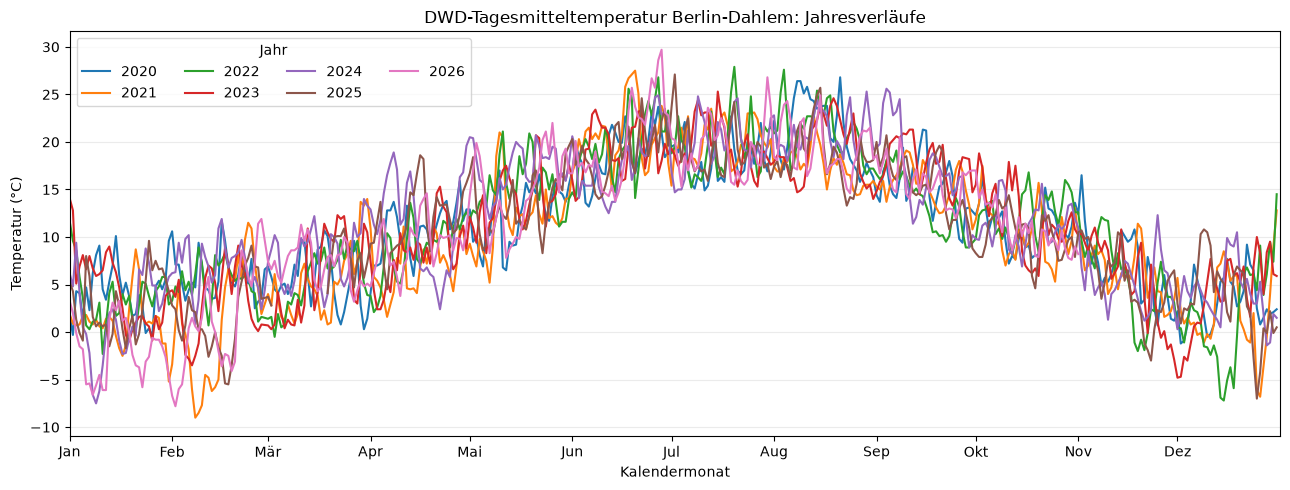

In [15]:
import matplotlib.pyplot as plt

jahre = sorted(wetter["date"].dt.year.dropna().unique())
farben = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(13, 5))

for index, jahr in enumerate(jahre):
    daten_jahr = wetter.loc[wetter["date"].dt.year == jahr]
    x_datum = pd.to_datetime(
        "2020-" + daten_jahr["date"].dt.strftime("%m-%d"),
        format="%Y-%m-%d",
    )
    ax.plot(
        x_datum,
        daten_jahr["temp_mean_c"],
        label=str(jahr),
        color=farben(index),
        linewidth=1.5,
    )

monatstermine = pd.date_range("2020-01-01", "2020-12-01", freq="MS")
ax.set_xticks(monatstermine, ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-01-01"))
ax.set_title("DWD-Tagesmitteltemperatur Berlin-Dahlem: Jahresverläufe")
ax.set_xlabel("Kalendermonat")
ax.set_ylabel("Temperatur (°C)")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Jahr", ncols=4)
fig.tight_layout()
plt.show()

,mittlere_bandbreite,median_bandbreite,anzahl_kalendertage
saison,,,
Winter,8.22,8.06,90
Frühling,6.95,6.69,92
Sommer,5.80,5.90,92
Herbst,5.43,5.40,91


Winter/Sommer-Verhältnis der mittleren Bandbreite: 1.42


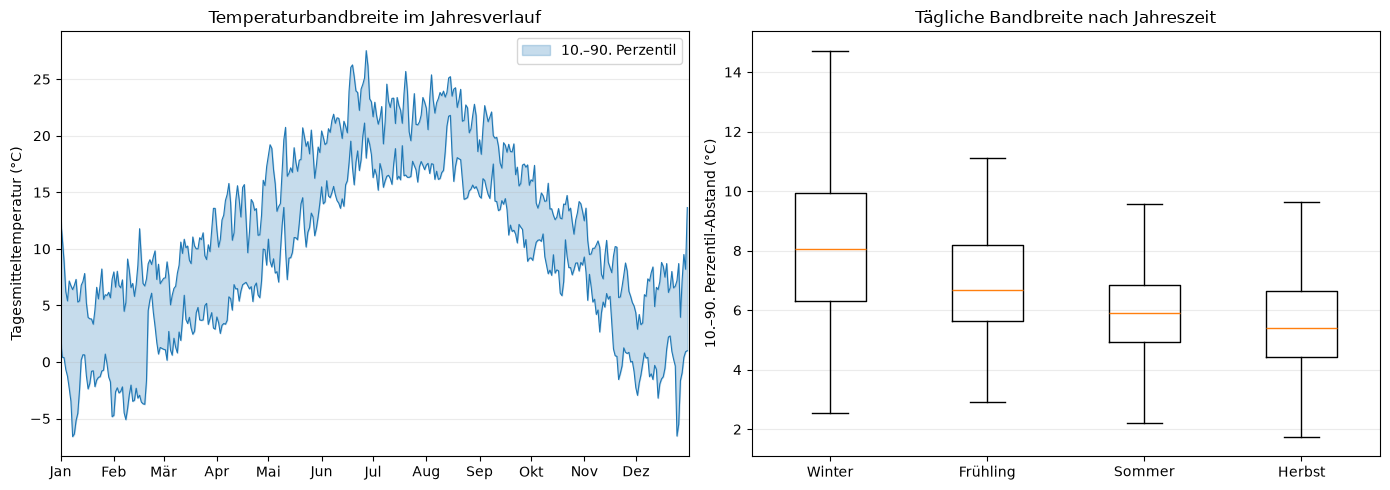

In [16]:
# Kalenderdatum unabhängig vom Jahr auf eine gemeinsame Jan-Dez-Achse legen
temperaturen = wetter.loc[wetter["temp_mean_c"].notna(), ["date", "temp_mean_c"]].copy()
temperaturen["kalendertag"] = pd.to_datetime(
    "2020-" + temperaturen["date"].dt.strftime("%m-%d"),
    format="%Y-%m-%d",
)

# Interannuelle Bandbreite je Kalendertag
tage = temperaturen.groupby("kalendertag")["temp_mean_c"].agg(
    anzahl_jahre="count",
    p10=lambda werte: werte.quantile(0.10),
    p90=lambda werte: werte.quantile(0.90),
)
tage["bandbreite_c"] = tage["p90"] - tage["p10"]

# Für vergleichbare Tageswerte nur Kalendertage mit mindestens 5 Messjahren verwenden
tage = tage.loc[tage["anzahl_jahre"] >= 5].copy()

saison_nach_monat = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Frühling", 4: "Frühling", 5: "Frühling",
    6: "Sommer", 7: "Sommer", 8: "Sommer",
    9: "Herbst", 10: "Herbst", 11: "Herbst",
}
saisons = ["Winter", "Frühling", "Sommer", "Herbst"]
tage["saison"] = tage.index.month.map(saison_nach_monat)

auswertung = tage.groupby("saison")["bandbreite_c"].agg(
    mittlere_bandbreite="mean",
    median_bandbreite="median",
    anzahl_kalendertage="count",
).reindex(saisons)

display(auswertung.round(2))

winter = auswertung.loc["Winter", "mittlere_bandbreite"]
sommer = auswertung.loc["Sommer", "mittlere_bandbreite"]
print(f"Winter/Sommer-Verhältnis der mittleren Bandbreite: {winter / sommer:.2f}")

# Grafische Darstellung
fig, (ax_band, ax_saison) = plt.subplots(1, 2, figsize=(14, 5))

ax_band.fill_between(
    tage.index, tage["p10"], tage["p90"],
    alpha=0.25, color="tab:blue", label="10.–90. Perzentil",
)
ax_band.plot(tage.index, tage["p10"], color="tab:blue", linewidth=0.8)
ax_band.plot(tage.index, tage["p90"], color="tab:blue", linewidth=0.8)
ax_band.set_xticks(
    monatstermine,
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"],
)
ax_band.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-01-01"))
ax_band.set_title("Temperaturbandbreite im Jahresverlauf")
ax_band.set_ylabel("Tagesmitteltemperatur (°C)")
ax_band.legend()
ax_band.grid(axis="y", alpha=0.25)

werte_nach_saison = [
    tage.loc[tage["saison"] == saison, "bandbreite_c"].to_numpy()
    for saison in saisons
]
ax_saison.boxplot(werte_nach_saison, tick_labels=saisons, showfliers=False)
ax_saison.set_title("Tägliche Bandbreite nach Jahreszeit")
ax_saison.set_ylabel("10.–90. Perzentil-Abstand (°C)")
ax_saison.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()